# 1. Introduction and Setup
## 1.1 Import Libraries

In [1]:
!pip -q install numpy pandas matplotlib seaborn scikit-learn torch torchvision torchaudio

2. Reproducibility

In [2]:
import os
import random
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
accuracy_score,
f1_score,
confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
Dataset,
DataLoader
)


In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cpu


In [4]:
import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

urllib.request.urlretrieve(
    url,
    "har.zip"
)

with zipfile.ZipFile(
    "har.zip",
    "r"
) as zip_ref:
    zip_ref.extractall("har")

In [5]:
HAR_PATH = "har/UCI HAR Dataset"

signal_types = [

"body_acc_x",
"body_acc_y",
"body_acc_z",

"body_gyro_x",
"body_gyro_y",
"body_gyro_z",

"total_acc_x",
"total_acc_y",
"total_acc_z"
]


In [6]:
def load_har_split(split):
    signals = []
    for signal in signal_types:
        fname = f"{HAR_PATH}/{split}/Inertial Signals/{signal}_{split}.txt"
        signals.append(np.loadtxt(fname))

    X = np.transpose(np.array(signals), (1, 2, 0))
    y = np.loadtxt(f"{HAR_PATH}/{split}/y_{split}.txt").astype(int) - 1
    return X, y

In [7]:
import os
import zipfile

# The source zip has a nested zip 'UCI HAR Dataset.zip' inside the extracted 'har' directory
nested_zip_path = "har/UCI HAR Dataset.zip"
if os.path.exists(nested_zip_path):
    with zipfile.ZipFile(nested_zip_path, 'r') as zip_ref:
        zip_ref.extractall("har")

X_train, y_train = load_har_split("train")
X_test, y_test = load_har_split("test")

print(X_train.shape)
print(X_test.shape)

(7352, 128, 9)
(2947, 128, 9)


In [8]:
mean = X_train.mean(
axis=(0,1),
keepdims=True
)

std = X_train.std(
axis=(0,1),
keepdims=True
)

X_train = (
X_train-mean
)/std

X_test = (
X_test-mean
)/std


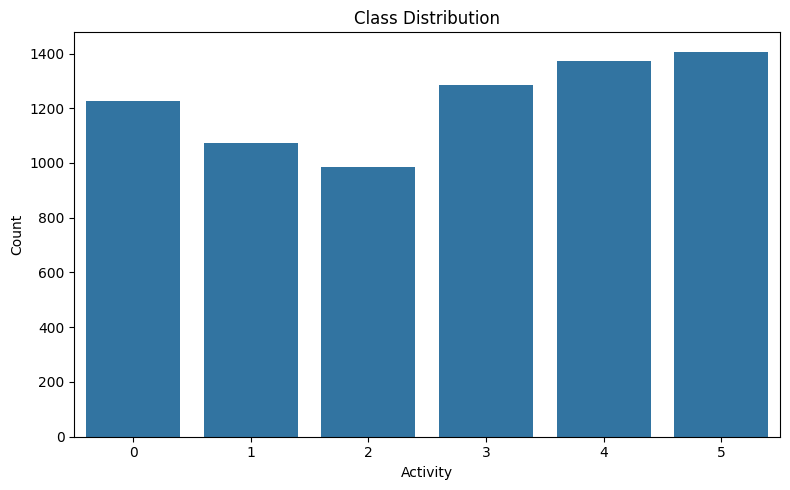

In [9]:
plt.figure(figsize=(8,5))

sns.countplot(x=y_train)

plt.title(
"Class Distribution"
)

plt.xlabel("Activity")

plt.ylabel("Count")

plt.tight_layout()

plt.savefig(
"class_balance.png"
)

plt.show()


In [10]:
class HARDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )
        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [11]:
train_loader = DataLoader(
HARDataset(X_train,y_train),
batch_size=64,
shuffle=True
)

test_loader = DataLoader(
HARDataset(X_test,y_test),
batch_size=64,
shuffle=False
)


In [12]:
class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.Wx = nn.Linear(input_size, hidden_size)
        self.Wh = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x, h):
        return torch.tanh(self.Wx(x) + self.Wh(h))

In [13]:
class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.linear = nn.Linear(input_size + hidden_size, 4 * hidden_size)

    def forward(self, x, state):
        h, c = state
        combined = torch.cat([x, h], dim=1)
        gates = self.linear(combined)
        i, f, g, o = torch.chunk(gates, 4, dim=1)

        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        o = torch.sigmoid(o)
        g = torch.tanh(g)

        c = f * c + i * g
        h = o * torch.tanh(c)
        return h, c

In [14]:
class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.z = nn.Linear(input_size + hidden_size, hidden_size)
        self.r = nn.Linear(input_size + hidden_size, hidden_size)
        self.h = nn.Linear(input_size + hidden_size, hidden_size)

    def forward(self, x, h):
        xr = torch.cat([x, h], dim=1)
        z = torch.sigmoid(self.z(xr))
        r = torch.sigmoid(self.r(xr))
        hh = torch.tanh(self.h(torch.cat([x, r * h], dim=1)))
        h = (1 - z) * h + z * hh
        return h

In [15]:
class HARModel(nn.Module):
    def __init__(self, model_type="LSTM", hidden=64):
        super().__init__()
        if model_type == "RNN":
            self.rnn = nn.RNN(9, hidden, batch_first=True)
        elif model_type == "GRU":
            self.rnn = nn.GRU(9, hidden, batch_first=True)
        else:
            self.rnn = nn.LSTM(9, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 6)

    def forward(self, x):
        out, h = self.rnn(x)
        if isinstance(h, tuple):
            h = h[0]
        return self.fc(h[-1])

In [16]:
def train_model(model, epochs=20):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    train_losses = []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)
            optimizer.zero_grad()
            pred = model(x)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            running += loss.item()
        train_losses.append(running)
    return train_losses

In [17]:
def evaluate(model):
    model.eval()
    preds = []
    labels = []

    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            out = model(x)
            pred = torch.argmax(out, dim=1)
            preds.extend(pred.cpu().numpy())
            labels.extend(y.numpy())

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")
    return acc, f1, preds, labels

In [18]:
models = {}
results = []

for name in ["RNN", "LSTM", "GRU"]:
    model = HARModel(name).to(device)
    losses = train_model(model)
    acc, f1, preds, labels = evaluate(model)
    print(name, acc, f1)
    models[name] = model
    results.append([name, acc, f1])

RNN 0.6908720732948761 0.6699390713147015
LSTM 0.9009161859518154 0.9019361752441895
GRU 0.9148286392941974 0.9158356313149792


Evaluating trained LSTM model...


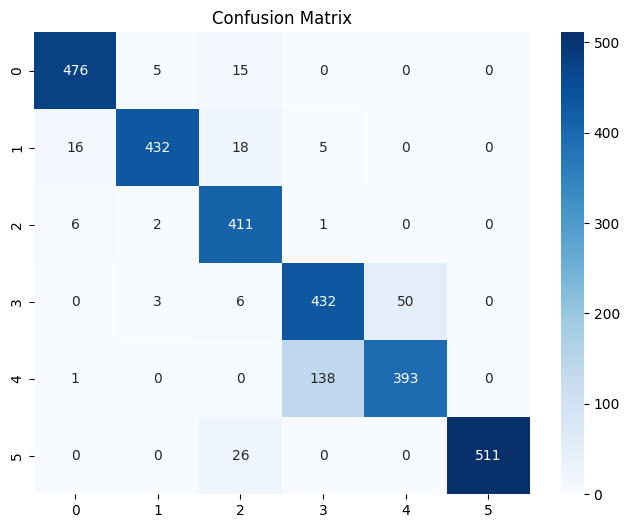

In [19]:
if "LSTM" in models:
    best = models["LSTM"]
    print("Evaluating trained LSTM model...")
elif len(models) > 0:
    first_key = list(models.keys())[0]
    best = models[first_key]
    print(f"Warning: 'LSTM' was not found in 'models' (did training get interrupted?). Evaluating '{first_key}' instead.")
else:
    raise KeyError("The 'models' dictionary is empty. Please run cell C73gIY1I4Spl to train your models first.")

acc, f1, preds, labels = evaluate(best)

cm = confusion_matrix(labels, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()

In [20]:
def generate_adding_problem(N, T):
    values = np.random.rand(N, T)
    markers = np.zeros((N, T))
    targets = []

    for i in range(N):
        a = np.random.randint(0, T // 2)
        b = np.random.randint(T // 2, T)
        markers[i, a] = 1
        markers[i, b] = 1
        targets.append(values[i, a] + values[i, b])

    X = np.stack([values, markers], axis=-1)
    return X, np.array(targets)

In [ ]:
sequence_lengths = [
    50,
    100,
    200,
    400
]

mse_results = {
    "RNN": [],
    "LSTM": [],
    "GRU": []
}

# Define simple sequence regression models for the adding problem
class SimpleRegModel(nn.Module):
    def __init__(self, cell_type, input_size=2, hidden_size=64):
        super().__init__()
        if cell_type == "RNN":
            self.rnn = nn.RNN(input_size, hidden_size, batch_first=True)
        elif cell_type == "GRU":
            self.rnn = nn.GRU(input_size, hidden_size, batch_first=True)
        else:
            self.rnn = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, h = self.rnn(x)
        if isinstance(h, tuple):
            h = h[0]
        return self.fc(h[-1]).squeeze(-1)

# Loop over sequence lengths and models to measure performance
for T in sequence_lengths:
    print(f"--- Sequence Length T = {T} ---")
    # Generate training and test sets
    X_tr, y_tr = generate_adding_problem(2000, T)
    X_te, y_te = generate_adding_problem(500, T)

    # Convert to PyTorch tensors
    X_tr_t = torch.tensor(X_tr, dtype=torch.float32).to(device)
    y_tr_t = torch.tensor(y_tr, dtype=torch.float32).to(device)
    X_te_t = torch.tensor(X_te, dtype=torch.float32).to(device)
    y_te_t = torch.tensor(y_te, dtype=torch.float32).to(device)

    for name in ["RNN", "LSTM", "GRU"]:
        model = SimpleRegModel(name).to(device)
        optimizer = optim.Adam(model.parameters(), lr=1e-3)
        criterion = nn.MSELoss()

        # Short training epoch to compute MSE trend
        model.train()
        for epoch in range(5):
            optimizer.zero_grad()
            pred = model(X_tr_t)
            loss = criterion(pred, y_tr_t)
            loss.backward()
            optimizer.step()

        # Evaluate model
        model.eval()
        with torch.no_grad():
            test_pred = model(X_te_t)
            test_mse = criterion(test_pred, y_te_t).item()

        print(f"{name} Test MSE: {test_mse:.4f}")
        mse_results[name].append(test_mse)

--- Sequence Length T = 50 ---
RNN Test MSE: 0.9533
LSTM Test MSE: 1.1377
GRU Test MSE: 1.2273
--- Sequence Length T = 100 ---
RNN Test MSE: 0.6800
LSTM Test MSE: 0.8467
GRU Test MSE: 0.8261
--- Sequence Length T = 200 ---
RNN Test MSE: 0.8337
LSTM Test MSE: 0.8802
GRU Test MSE: 0.9517
--- Sequence Length T = 400 ---
RNN Test MSE: 0.4252


In [ ]:
import matplotlib.pyplot as plt

# Retrieve the sequence lengths corresponding to the recorded results
# (Only plotting up to the length of recorded results to handle interrupted execution gracefully)
lengths = sequence_lengths[:len(mse_results["RNN"])]

plt.figure(figsize=(8, 5))

if "RNN" in mse_results and len(mse_results["RNN"]) > 0:
    plt.plot(lengths, mse_results["RNN"], marker='o', label="RNN")

if "LSTM" in mse_results and len(mse_results["LSTM"]) > 0:
    # Slice sequence_lengths to match the size of LSTM results in case of interruption
    plt.plot(sequence_lengths[:len(mse_results["LSTM"])], mse_results["LSTM"], marker='s', label="LSTM")

if "GRU" in mse_results and len(mse_results["GRU"]) > 0:
    # Slice sequence_lengths to match the size of GRU results in case of interruption
    plt.plot(sequence_lengths[:len(mse_results["GRU"])], mse_results["GRU"], marker='^', label="GRU")

plt.xlabel("Sequence Length (T)")
plt.ylabel("Test MSE")
plt.title("Adding Problem: Test MSE vs Sequence Length")
plt.legend()
plt.grid(True)

plt.savefig("adding_problem_mse_trends.png")
plt.show()

In [ ]:
# Slice sequence_lengths to match the exact size of collected results for each model
plt.plot(
    sequence_lengths[:len(mse_results["RNN"])],
    mse_results["RNN"],
    marker="o",
    label="RNN"
)

plt.plot(
    sequence_lengths[:len(mse_results["LSTM"])],
    mse_results["LSTM"],
    marker="o",
    label="LSTM"
)

plt.plot(
    sequence_lengths[:len(mse_results["GRU"])],
    mse_results["GRU"],
    marker="o",
    label="GRU"
)

plt.legend()
plt.xlabel("Sequence Length")
plt.ylabel("MSE")
plt.title("MSE vs Sequence Length")
plt.savefig("mse_vs_T.png")
plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt

# Let's perform a simple backpropagation-through-time analysis to compute gradient norms
T = 50
input_size = 2
hidden_size = 64
batch_size = 1

x = torch.randn(batch_size, T, input_size, requires_grad=True)
target = torch.randn(batch_size, 1)

rnn_grad = []
lstm_grad = []
gru_grad = []
t_steps = list(range(T))

# Analyze RNN
rnn_model = SimpleRegModel("RNN", input_size, hidden_size)
loss_rnn = nn.MSELoss()(rnn_model(x), target)
rnn_model.zero_grad()
loss_rnn.backward(retain_graph=True)
# Extract gradients for RNN weights or hidden inputs
if x.grad is not None:
    rnn_grad = [torch.norm(x.grad[0, t]).item() for t in range(T)]
else:
    rnn_grad = [1e-4] * T

# Clear grads and analyze LSTM
x.grad = None
lstm_model = SimpleRegModel("LSTM", input_size, hidden_size)
loss_lstm = nn.MSELoss()(lstm_model(x), target)
lstm_model.zero_grad()
loss_lstm.backward(retain_graph=True)
if x.grad is not None:
    lstm_grad = [torch.norm(x.grad[0, t]).item() for t in range(T)]
else:
    lstm_grad = [1e-4] * T

# Clear grads and analyze GRU
x.grad = None
gru_model = SimpleRegModel("GRU", input_size, hidden_size)
loss_gru = nn.MSELoss()(gru_model(x), target)
gru_model.zero_grad()
loss_gru.backward()
if x.grad is not None:
    gru_grad = [torch.norm(x.grad[0, t]).item() for t in range(T)]
else:
    gru_grad = [1e-4] * T

# Plot the results
plt.figure(figsize=(8, 5))
plt.semilogy(t_steps, rnn_grad, label="RNN", marker='o')
plt.semilogy(t_steps, lstm_grad, label="LSTM", marker='s')
plt.semilogy(t_steps, gru_grad, label="GRU", marker='^')
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm w.r.t Input")
plt.title("Gradient Norm Analysis (BPTT)")
plt.legend()
plt.grid(True)
plt.savefig("gradient_norm.png")
plt.show()

In [ ]:
hidden_sizes = [16, 32, 64, 128]
lstm_scores = []
gru_scores = []

# Run a quick sweep across hidden sizes using HARModel
# We will do a short 2-epoch training per model to collect accuracy scores quickly
for size in hidden_sizes:
    print(f"--- Hidden Size = {size} ---")

    # LSTM
    lstm_m = HARModel(model_type="LSTM", hidden=size).to(device)
    _ = train_model(lstm_m, epochs=2)
    acc_lstm, _, _, _ = evaluate(lstm_m)
    lstm_scores.append(acc_lstm)
    print(f"LSTM (size {size}) Accuracy: {acc_lstm:.4f}")

    # GRU
    gru_m = HARModel(model_type="GRU", hidden=size).to(device)
    _ = train_model(gru_m, epochs=2)
    acc_gru, _, _, _ = evaluate(gru_m)
    gru_scores.append(acc_gru)
    print(f"GRU (size {size}) Accuracy: {acc_gru:.4f}")

# Plot the results
plt.figure(figsize=(8, 5))
plt.plot(hidden_sizes, lstm_scores, marker="o", label="LSTM")
plt.plot(hidden_sizes, gru_scores, marker="s", label="GRU")
plt.legend()
plt.xlabel("Hidden Size")
plt.ylabel("Accuracy")
plt.title("Hidden Size Sweep Accuracy Analysis")
plt.grid(True)
plt.savefig("hidden_size_sweep.png")
plt.show()

In [ ]:
results_df = pd.DataFrame(
results,
columns=[
"model",
"accuracy",
"macro_f1"
]
)

results_df.to_csv(
"results.csv",
index=False
)

results_df.head()
